In [3]:
!pip install pandas numpy scikit-learn xgboost imbalanced-learn shap kagglehub

In [5]:
import pandas as pd
import kagglehub
import os

# Download the dataset from the Give Me Some Credit competition
try:
    path = kagglehub.dataset_download("brycecf/give-me-some-credit-dataset")
    csv_path = os.path.join(path, 'cs-training.csv')
    df = pd.read_csv(csv_path, index_col=0)
    print("Dataset loaded successfully!")
    display(df.head())
except Exception as e:
    print(f"An error occurred while downloading the dataset: {e}")
    print("Please make sure the file is uploaded manually if you do not have Kaggle credentials configured.")

Using Colab cache for faster access to the 'give-me-some-credit-dataset' dataset.
Dataset loaded successfully!


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
print(f"Total Rows and Columns: {df.shape}")
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")

Total Rows and Columns: (150000, 11)
Total Rows: 150000
Total Columns: 11


In [9]:
# 1. Impute missing values with median first so engineered features won't inherit NaNs
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

# 2. Feature Engineering
df['DebtPerIncome'] = df['DebtRatio'] * df['MonthlyIncome']
df['RevolvingUtilizationRatio'] = df['RevolvingUtilizationOfUnsecuredLines']
df['TotalDelinquencies'] = (
    df['NumberOfTime30-59DaysPastDueNotWorse'] +
    df['NumberOfTimes90DaysLate'] +
    df['NumberOfTime60-89DaysPastDueNotWorse']
)

# 3. Separate Features and Target
X = df.drop(columns=['SeriousDlqin2yrs'])
y = df['SeriousDlqin2yrs']

# 4. Stratified Train-Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Handle Class Imbalance using SMOTE on training data
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Data preprocessed and SMOTE applied successfully!")
print(f"Resampled training data shape: {X_train_resampled.shape}")

Data preprocessed and SMOTE applied successfully!
Resampled training data shape: (223958, 13)


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, auc

# 1. Scale features for optimal model performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# 2. Train Logistic Regression (Baseline)
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train_resampled)

# 3. Train Tree Ensemble (Random Forest)
print("Training Tree Ensemble...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train_scaled, y_train_resampled)

# 4. Comprehensive Evaluation Function
def evaluate_model(model, X_te, y_te, name="Model"):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    print(f"\n================ {name} ================")
    print(classification_report(y_te, y_pred, target_names=['Creditworthy (0)', 'Default Risk (1)']))

    roc_auc = roc_auc_score(y_te, y_prob)
    precision, recall, _ = precision_recall_curve(y_te, y_prob)
    pr_auc = auc(recall, precision)

    print(f"ROC-AUC Score: {roc_auc:.4f}")
    print(f"Precision-Recall AUC (PR-AUC): {pr_auc:.4f}")

evaluate_model(lr_model, X_test_scaled, y_test, name="Logistic Regression")
evaluate_model(rf_model, X_test_scaled, y_test, name="Tree Ensemble (Random Forest)")

Training Logistic Regression...
Training Tree Ensemble...

================ Logistic Regression ================
                  precision    recall  f1-score   support

Creditworthy (0)       0.96      0.80      0.87     27995
Default Risk (1)       0.15      0.50      0.24      2005

        accuracy                           0.78     30000
       macro avg       0.56      0.65      0.56     30000
    weighted avg       0.90      0.78      0.83     30000

ROC-AUC Score: 0.7127
Precision-Recall AUC (PR-AUC): 0.2217

================ Tree Ensemble (Random Forest) ================
                  precision    recall  f1-score   support

Creditworthy (0)       0.98      0.82      0.89     27995
Default Risk (1)       0.22      0.72      0.34      2005

        accuracy                           0.81     30000
       macro avg       0.60      0.77      0.62     30000
    weighted avg       0.93      0.81      0.85     30000

ROC-AUC Score: 0.8527
Precision-Recall AUC (PR-AUC): 0.3476


Top Feature Importances:
                                 Feature  Importance
0   RevolvingUtilizationOfUnsecuredLines    0.248556
12                    TotalDelinquencies    0.198537
11             RevolvingUtilizationRatio    0.188078
9                     NumberOfDependents    0.159423
6                NumberOfTimes90DaysLate    0.067198
2   NumberOfTime30-59DaysPastDueNotWorse    0.046436
1                                    age    0.033114
7           NumberRealEstateLoansOrLines    0.014453
3                              DebtRatio    0.010923
8   NumberOfTime60-89DaysPastDueNotWorse    0.010724


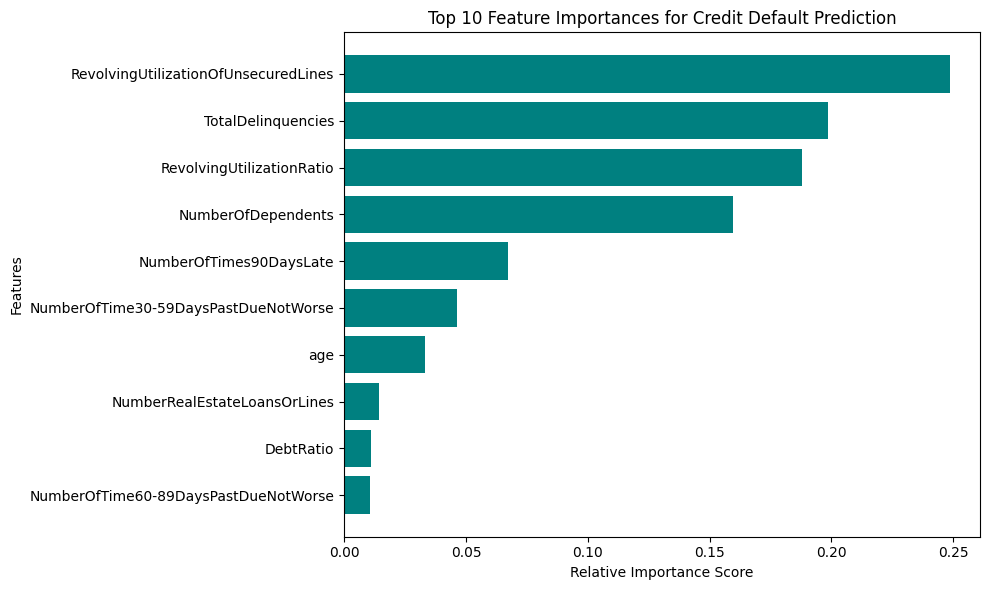

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
features = X.columns

# Create a summary DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("Top Feature Importances:")
print(feature_importance_df.head(10))

# Plot the top features
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'].head(10)[::-1],
         feature_importance_df['Importance'].head(10)[::-1],
         color='teal')
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Feature Importances for Credit Default Prediction")
plt.tight_layout()
plt.show()

Which Error is Worse and Why?
In credit risk modeling, we deal with two types of errors:

False Positive (Type I Error): Predicting an applicant will default when they actually would have paid successfully. Cost: The bank loses a good customer and potential interest revenue.

False Negative (Type II Error): Predicting an applicant is creditworthy when they actually end up defaulting. Cost: The bank issues the loan and loses a massive amount of capital when the borrower fails to repay.

Conclusion: A False Negative is significantly worse for financial institutions. While turning away a good applicant hurts growth, issuing a loan to a defaulter results in direct financial loss and bad debt. Therefore, our model optimization prioritizes a high recall (catching as many defaults as possible) even if it leads to more false positives.